# Soft vs. Hard PINNs — Reproduction & Results

This notebook is the **executed results index** for the GitHub repository. It reads **actual saved** outputs from two experiments:

- **Paper-aligned analytic case:** no-source heat equation from Bowman et al. (2023), Eq. (12), with 10x32 Tanh; one matched Soft/Hard pair.
- **Manufactured-source extension:** five matched random seeds; 3x64 Tanh network.

**Scope:** this is **not** a reproduction of original PAC1D laser or insulated-boundary datasets. The original data are not public, and our Eq. (12) case uses the analytically compatible Dirichlet traces. See README for deviations.

No Matplotlib is used. Training code and full experiment settings are in `paper_aligned.py` and `run_seed_batch.py`. The precomputed outputs below come from completed runs.

In [1]:
from pathlib import Path
import json
from PIL import Image
from IPython.display import display
ROOT = Path.cwd()
PAPER = ROOT / 'results' / 'paper_aligned'
MULTI = ROOT / 'results' / 'multi_seed'
assert (PAPER/'metrics.json').exists() and (MULTI/'summary.json').exists(), 'Open this notebook from the project root.'
print('Project root:', ROOT)

Project root: /mnt/data/PINN_Heat_Final_GitHub


## 1. Paper-aligned analytical no-source test

Reference: Bowman, B. et al. (2023), *Algorithms* 16(9), 428, [DOI](https://doi.org/10.3390/a16090428), Eq. (12). We use:

\[
u_t-0.1 u_{xx}=0,\qquad u^*(x,t)=e^{-0.1\pi^2t}\sin(\pi x).
\]

Soft uses an IC/BC penalty (weight 21 relative to PDE loss). Hard uses
\[
u_\theta(x,t)=\sin(\pi x)+t x(1-x)N_\theta(x,t).
\]

Both use matched 10x32 Tanh cores, 2,000 Adam steps, then 120 nominal L-BFGS iterations, and are evaluated on a 101x101 grid. Reported errors are from **one** paired seed.

In [2]:
paper=json.loads((PAPER/'metrics.json').read_text())
print(f"{'Metric':<29} {'Soft':>16} {'Hard':>16}")
print('-'*64)
for key in ('relative_l2','pde_rmse_heldout','ic_rmse','bc_rmse','r2'):
    scale=100 if key=='relative_l2' else 1
    postfix='%' if scale==100 else ''
    print(f"{key:<29} {paper['soft'][key]*scale:>15.7f}{postfix:<1} {paper['hard'][key]*scale:>15.7f}{postfix:<1}")

Metric                                    Soft             Hard
----------------------------------------------------------------
relative_l2                         0.3302545%       0.0083727%
pde_rmse_heldout                    0.0196419        0.0008022 
ic_rmse                             0.0018124        0.0000000 
bc_rmse                             0.0014874        0.0000001 
r2                                  0.9999577        1.0000000 


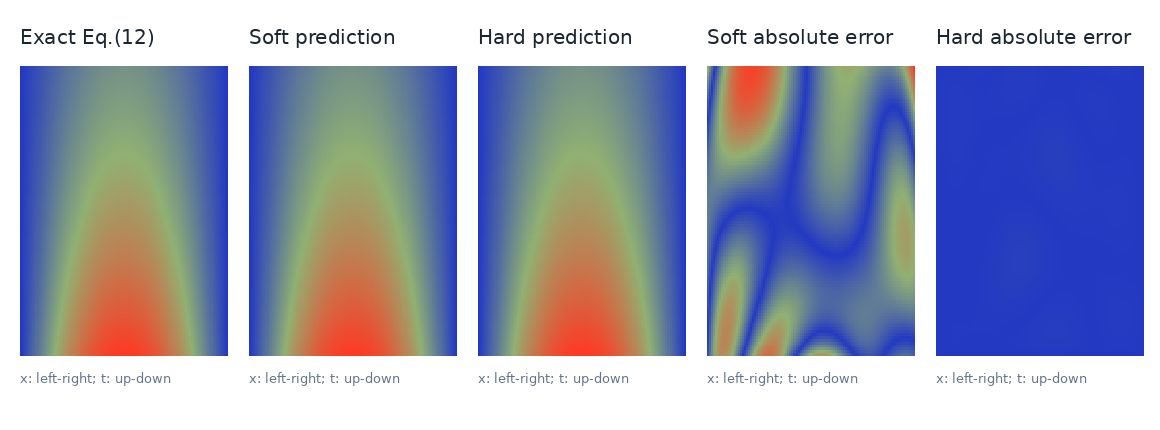

In [3]:
display(Image.open(PAPER/'paper_aligned_predictions.png'))

## 2. Manufactured-source extension, seeds 1–5

Exact reference: \(u^*(x,t)=e^{-t}\sin(\pi x)+0.2t\sin(3\pi x)\); the known forcing is generated from this expression, and interior true temperatures are used **only for evaluation**. Both networks use 2,000 Adam epochs per seed, the same initial core weights and collocation stream, and fixed Soft weights of 10 for IC and BC.

In [4]:
multi=json.loads((MULTI/'summary.json').read_text())
for mode in ('soft','hard'):
    a=multi['numerical_results'][mode]
    print(f"{mode.title():<5}: relative L2 = {100*a['relative_l2']['mean']:.4f} ± {100*a['relative_l2']['sd']:.4f}% (n=5)")
    print(f"       held-out PDE RMSE = {a['pde_rmse_heldout']['mean']:.6f} ± {a['pde_rmse_heldout']['sd']:.6f}")

Soft : relative L2 = 1.1009 ± 0.6064% (n=5)
       held-out PDE RMSE = 0.035820 ± 0.006857
Hard : relative L2 = 0.1331 ± 0.0559% (n=5)
       held-out PDE RMSE = 0.006587 ± 0.002231


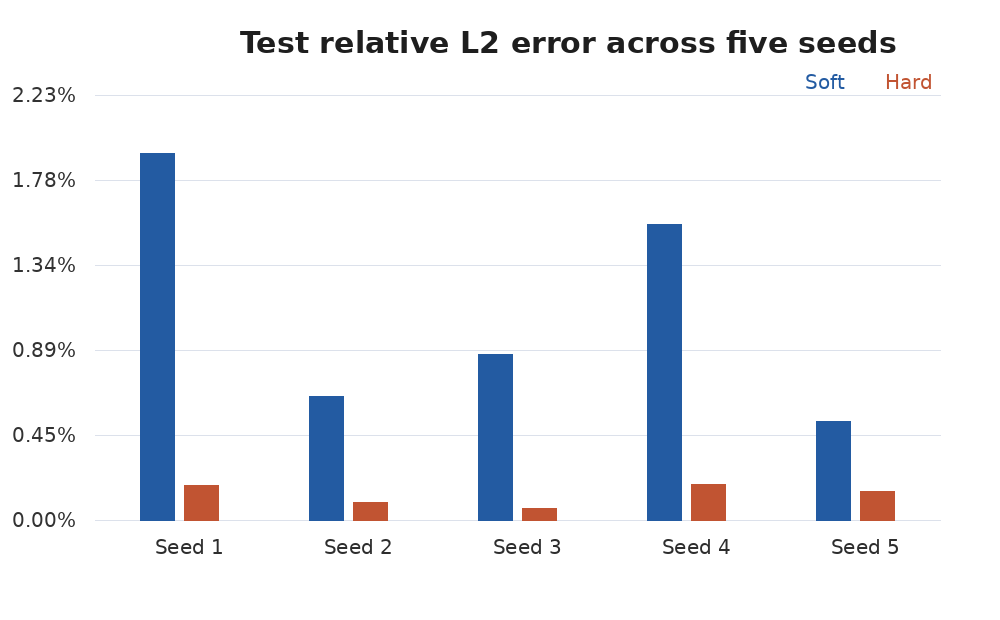

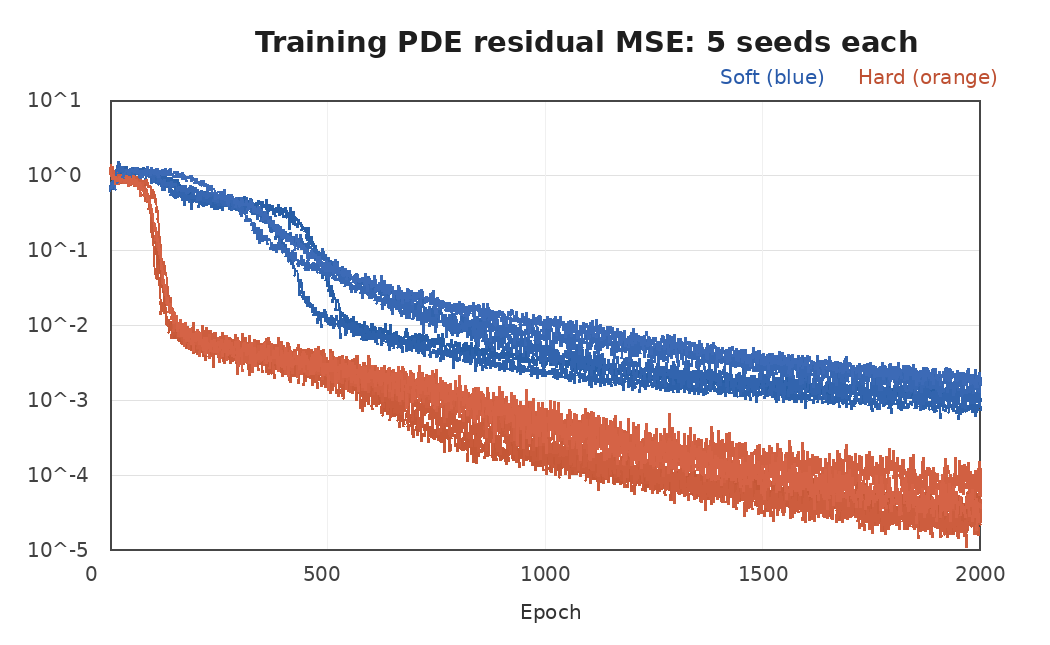

In [5]:
display(Image.open(MULTI/'relative_l2_by_seed.png'))
display(Image.open(MULTI/'pde_loss_all_seeds.png'))

## 3. Consistency checks and rerun options

All ten manufactured-source runs have 2,000 epoch logs; the paper-aligned pair has 2,000 Adam epochs and recorded L-BFGS closure evaluations. `validate_project.py` also verifies the analytical PDE residual and structural hard IC/BC constraints.

Set `RUN_TRAINING=True` **only when you intentionally want to recompute and overwrite results**. From a fresh clone, first install requirements. `run_seed_batch.py` skips completed seed checkpoints, allowing interrupted runs to resume.

In [6]:
import subprocess, sys
result = subprocess.run([sys.executable, 'validate_project.py'], cwd=ROOT, text=True, capture_output=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError('Project validation failed')

PASS: two exact PDE residuals, hard IC/BC, ten 2k-epoch histories, both paper-aligned runs, finite metrics



In [7]:
RUN_TRAINING=False  # Change only when you want to rerun all experiments.
if RUN_TRAINING:
    subprocess.check_call([sys.executable,'paper_aligned.py'],cwd=ROOT)
    subprocess.check_call([sys.executable,'run_seed_batch.py','1','2','3','4','5'],cwd=ROOT)
    subprocess.check_call([sys.executable,'summarize_multiseed.py'],cwd=ROOT)
else:
    print('No retraining requested: showing previously executed and verified results.')

No retraining requested: showing previously executed and verified results.
